# Section B — CIFAR-10 Robustness
Run all cells top-to-bottom. Set `QUICK_TEST=1` in the environment for a 2-epoch smoke test. See README.md.

In [1]:

!pip install torch torchvision matplotlib pandas numpy pillow python-docx

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 253.0/253.0 kB 6.8 MB/s eta 0:00:00


In [2]:

# Imports and reproducibility
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, transforms


SEED = 42
QUICK_TEST = False

RUN_SEEDS = [42] if QUICK_TEST else [42, 123, 2026]
FINAL_EPOCHS = 2 if QUICK_TEST else 60
PATIENCE = 10

DATA_DIR = "./data"
OUTPUT_DIR = Path("./section_b_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Seed:", SEED)
print("Run seeds:", RUN_SEEDS)
print("Maximum epochs:", FINAL_EPOCHS)
print("Device:", device)
print("PyTorch version:", torch.__version__)

Seed: 42
Run seeds: [42, 123, 2026]
Maximum epochs: 60
Device: cuda
PyTorch version: 2.11.0+cu130


In [3]:
#  Load CIFAR-10 and build train_small (500 imgs) -> 400 train / 100 val
raw_train = datasets.CIFAR10(root=DATA_DIR, train=True, download=True, transform=None)
raw_test = datasets.CIFAR10(root=DATA_DIR, train=False, download=True, transform=None)

CLASS_NAMES = raw_train.classes
targets = np.asarray(raw_train.targets)
rng_select = np.random.default_rng(SEED)
selected_indices = []
for class_id in range(10):
    class_indices = np.flatnonzero(targets == class_id)
    selected_indices.extend(rng_select.choice(class_indices, size=50, replace=False).tolist())
selected_indices = np.asarray(selected_indices)

rng_split = np.random.default_rng(SEED + 1)
train_indices, val_indices = [], []
for class_id in range(10):
    idx = selected_indices[targets[selected_indices] == class_id].copy()
    rng_split.shuffle(idx)
    train_indices.extend(idx[:40].tolist())
    val_indices.extend(idx[40:].tolist())

assert len(train_indices) == 400 and len(val_indices) == 100
assert not set(train_indices) & set(val_indices)
print("train_small:", len(selected_indices), "| train:", len(train_indices),
      "| val:", len(val_indices), "| clean_test:", len(raw_test))

100%|██████████| 170M/170M [45:57<00:00, 61.8kB/s]


train_small: 500 | train: 400 | val: 100 | clean_test: 10000


In [4]:
#  shifted_test: fixed, seeded corruption of the 10,000 CIFAR-10 test images

from PIL import Image, ImageEnhance

class DeterministicShiftedCIFAR(Dataset):
    _cache = {}
    def __init__(self, base_dataset, seed=9000):
        key = (seed, len(base_dataset))
        if key not in DeterministicShiftedCIFAR._cache:
            path = OUTPUT_DIR / f"shifted_test_seed{seed}.npz"
            if path.exists():
                d = np.load(path); imgs, labels = d["images"], d["labels"]
            else:
                imgs, labels = self._build(base_dataset, seed)
                np.savez_compressed(path, images=imgs, labels=labels)
            DeterministicShiftedCIFAR._cache[key] = (imgs, labels)
        self.images, self.labels = DeterministicShiftedCIFAR._cache[key]

    @staticmethod
    def _build(base, seed):
        rng = np.random.default_rng(seed)
        out, labels = [], []
        for i in range(len(base)):
            img, y = base[i]
            # rotation up to ±25°
            img = img.rotate(float(rng.uniform(-25, 25)),
                             resample=Image.Resampling.BILINEAR, fillcolor=(0, 0, 0))
            # brightness and contrast
            img = ImageEnhance.Brightness(img).enhance(float(rng.uniform(0.6, 1.4)))
            img = ImageEnhance.Contrast(img).enhance(float(rng.uniform(0.6, 1.4)))
            arr = np.array(img)
            # hidden corruption: grayscale OR channel swap
            if rng.random() < 0.5:
                g = 0.299 * arr[..., 0] + 0.587 * arr[..., 1] + 0.114 * arr[..., 2]
                arr = np.repeat(g[..., None], 3, axis=2).astype(np.uint8)
            else:
                perm = tuple(rng.permutation(3))
                while perm == (0, 1, 2):
                    perm = tuple(rng.permutation(3))
                arr = arr[..., list(perm)]
            # rectangular occlusion
            h, w = arr.shape[:2]
            area = float(rng.uniform(0.20, 0.30)) * h * w
            ar = float(np.exp(rng.uniform(np.log(0.5), np.log(2.0))))
            oh = int(np.clip(round(np.sqrt(area * ar)), 1, h))
            ow = int(np.clip(round(area / oh), 1, w))
            y0 = int(rng.integers(0, h - oh + 1)); x0 = int(rng.integers(0, w - ow + 1))
            arr = arr.copy(); arr[y0:y0 + oh, x0:x0 + ow] = 0
            out.append(arr); labels.append(y)
        return np.stack(out).astype(np.uint8), np.asarray(labels)

    def __len__(self): return len(self.labels)
    def __getitem__(self, i):
        return Image.fromarray(self.images[i]), int(self.labels[i])

In [5]:
#  Training augmentation (on the fly, training data only) and loaders
CIFAR_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR_STD = (0.2470, 0.2435, 0.2616)

class AddGaussianNoise:
    def __init__(self, std=0.04, p=0.30):
        self.std, self.p = std, p
    def __call__(self, tensor):
        if torch.rand(1).item() < self.p:
            tensor = tensor + torch.randn_like(tensor) * self.std
        return tensor.clamp(0, 1)

GEO_CFGS = ("geometric", "geo_photo", "mixup", "geo_photo_erasing", "final", "final_gray")
PHOTO_CFGS = ("photometric", "geo_photo", "mixup", "geo_photo_erasing", "final", "final_gray")
ERASE_CFGS = ("geo_photo_erasing", "final", "final_gray")

def make_train_transform(config):
    ops = []
    if config in GEO_CFGS:
        ops += [transforms.RandomCrop(32, padding=4),
                transforms.RandomHorizontalFlip(p=0.5),
                transforms.RandomRotation(20)]
    if config in PHOTO_CFGS:
        ops += [transforms.ColorJitter(brightness=0.25, contrast=0.25, saturation=0.20),
                transforms.RandomApply([transforms.GaussianBlur(kernel_size=3, sigma=(0.1, 1.0))], p=0.25)]
    if config == "final_gray":
        ops += [transforms.RandomGrayscale(p=0.1)]
    ops += [transforms.ToTensor()]
    if config in PHOTO_CFGS:
        ops += [AddGaussianNoise(std=0.04, p=0.30)]
    if config in ERASE_CFGS:
        ops += [transforms.RandomErasing(p=0.25, scale=(0.02, 0.20), ratio=(0.5, 2.0), value=0)]
    ops += [transforms.Normalize(CIFAR_MEAN, CIFAR_STD)]
    return transforms.Compose(ops)

eval_transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize(CIFAR_MEAN, CIFAR_STD)])

class CIFARIndexDataset(Dataset):
    def __init__(self, base_dataset, indices, transform):
        self.base, self.indices, self.transform = base_dataset, list(indices), transform
    def __len__(self): return len(self.indices)
    def __getitem__(self, item):
        image, label = self.base[self.indices[item]]
        return (self.transform(image) if self.transform else image), label

class TransformedDataset(Dataset):
    def __init__(self, ds, transform): self.ds, self.transform = ds, transform
    def __len__(self): return len(self.ds)
    def __getitem__(self, i):
        im, y = self.ds[i]
        return self.transform(im), y

def make_train_val_loaders(config, seed, batch_size=32):
    """Training + validation only. No test data touched here."""
    train_ds = CIFARIndexDataset(raw_train, train_indices, make_train_transform(config))
    val_ds = CIFARIndexDataset(raw_train, val_indices, eval_transform)
    gen = torch.Generator(); gen.manual_seed(seed)
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, generator=gen, num_workers=0)
    val_loader = DataLoader(val_ds, batch_size=128, shuffle=False, num_workers=0)
    return train_loader, val_loader

def make_test_loaders():
    """clean_test + shifted_test. Called ONLY from the final evaluation cell."""
    clean_ds = datasets.CIFAR10(root=DATA_DIR, train=False, download=False, transform=eval_transform)
    shifted_ds = TransformedDataset(DeterministicShiftedCIFAR(raw_test, seed=9000), eval_transform)
    return (DataLoader(clean_ds, batch_size=128, shuffle=False, num_workers=0),
            DataLoader(shifted_ds, batch_size=128, shuffle=False, num_workers=0))

In [6]:
# Inception-style CNN (< 1M parameters)
class ConvBNReLU(nn.Module):
    def __init__(self, in_ch, out_ch, kernel_size, padding=0):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size, padding=padding, bias=False),
            nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True))
    def forward(self, x): return self.net(x)

class InceptionBlock(nn.Module):
    def __init__(self, in_ch, c1, c3red, c3, c5red, c5, poolproj):
        super().__init__()
        self.branch1 = ConvBNReLU(in_ch, c1, 1)
        self.branch3 = nn.Sequential(ConvBNReLU(in_ch, c3red, 1), ConvBNReLU(c3red, c3, 3, padding=1))
        self.branch5 = nn.Sequential(ConvBNReLU(in_ch, c5red, 1), ConvBNReLU(c5red, c5, 5, padding=2))
        self.branch_pool = nn.Sequential(nn.AvgPool2d(3, stride=1, padding=1), ConvBNReLU(in_ch, poolproj, 1))
    def forward(self, x):
        return torch.cat([self.branch1(x), self.branch3(x), self.branch5(x), self.branch_pool(x)], dim=1)

class SmallInceptionCNN(nn.Module):
    def __init__(self, dropout=0.30):
        super().__init__()
        self.stem = ConvBNReLU(3, 32, 3, padding=1)
        self.inc1 = InceptionBlock(32, 16, 16, 24, 8, 12, 8)   # 60 channels
        self.pool1 = nn.MaxPool2d(2)                           # 16x16
        self.reduce = ConvBNReLU(60, 64, 3, padding=1)
        self.inc2 = InceptionBlock(64, 24, 16, 24, 8, 12, 8)   # 68 channels
        self.pool2 = nn.MaxPool2d(2)                           # 8x8
        self.final_conv = ConvBNReLU(68, 96, 3, padding=1)
        self.gap = nn.AdaptiveAvgPool2d(1)
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(96, 10)
    def forward(self, x):
        x = self.inc1(self.stem(x))
        x = self.pool1(x)
        x = self.inc2(self.reduce(x))
        x = self.pool2(x)
        x = self.gap(self.final_conv(x)).flatten(1)
        return self.classifier(self.dropout(x))

def count_trainable_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

n_params = count_trainable_parameters(SmallInceptionCNN())
print(f"Trainable parameters: {n_params:,}")
assert n_params <= 1_000_000, "Model exceeds the 1M parameter limit"

Trainable parameters: 112,714


In [7]:
# Evaluation and training (NO test data used here)
@torch.no_grad()
def evaluate(model, loader, criterion=None):
    model.eval()
    total, correct, loss_sum = 0, 0, 0.0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        logits = model(images)
        if criterion is not None:
            loss_sum += criterion(logits, labels).item() * labels.size(0)
        total += labels.size(0)
        correct += (logits.argmax(1) == labels).sum().item()
    return (loss_sum / total if criterion is not None else None), correct / total

def mixup_batch(images, labels, alpha=0.2):
    if alpha <= 0:
        return images, labels, labels, 1.0
    lam = float(np.random.beta(alpha, alpha))
    index = torch.randperm(images.size(0), device=images.device)
    return lam * images + (1 - lam) * images[index], labels, labels[index], lam

def train_one_run(config, seed, epochs=60, patience=10, use_mixup=False,
                  label_smoothing=0.0, weight_decay=1e-4):
    assert epochs <= 60, "Rule: maximum 60 epochs"
    seed_everything(seed)
    train_loader, val_loader = make_train_val_loaders(config, seed)
    model = SmallInceptionCNN(dropout=0.30).to(device)
    criterion = nn.CrossEntropyLoss(label_smoothing=label_smoothing)
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)

    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": [], "lr": []}
    best_val, best_epoch, best_state, stale = -1.0, 0, None, 0
    start = time.time()
    for epoch in range(epochs):
        model.train()
        total, correct, loss_sum = 0, 0, 0.0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad(set_to_none=True)
            if use_mixup:
                mixed, y_a, y_b, lam = mixup_batch(images, labels, alpha=0.2)
                logits = model(mixed)
                loss = lam * criterion(logits, y_a) + (1 - lam) * criterion(logits, y_b)
            else:
                logits = model(images)
                loss = criterion(logits, labels)
            loss.backward()
            optimizer.step()
            total += labels.size(0)
            loss_sum += loss.item() * labels.size(0)
            correct += (logits.argmax(1) == labels).sum().item()
        scheduler.step()

        val_loss, val_acc = evaluate(model, val_loader, criterion)
        history["train_loss"].append(loss_sum / total)
        history["train_acc"].append(correct / total)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        history["lr"].append(optimizer.param_groups[0]["lr"])

        if val_acc > best_val:
            best_val, best_epoch, stale = val_acc, epoch + 1, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            stale += 1
        if (epoch + 1) % 10 == 0 or epoch == 0:
            print(f"seed={seed} epoch={epoch+1:02d}/{epochs} "
                  f"train_acc={correct/total:.3f} val_acc={val_acc:.3f}")
        if stale >= patience:
            print(f"Early stopping at epoch {epoch+1}; best epoch={best_epoch}")
            break

    model.load_state_dict(best_state)          # checkpoint chosen by VALIDATION accuracy
    result = {"config": config, "seed": seed, "best_epoch": best_epoch,
              "best_val_acc": best_val, "trainable_params": n_params,
              "epochs_run": len(history["train_loss"]), "seconds": time.time() - start}
    return model, history, result

In [8]:
# Learning-curve plot (title, axis labels, legend)
def plot_history(history, title, save_path=None):
    epochs = np.arange(1, len(history["train_loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    axes[0].plot(epochs, history["train_loss"], label="Training loss")
    axes[0].plot(epochs, history["val_loss"], label="Validation loss")
    axes[0].set_title(f"{title}: Loss"); axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Cross-entropy loss")
    axes[1].plot(epochs, history["train_acc"], label="Training accuracy")
    axes[1].plot(epochs, history["val_acc"], label="Validation accuracy")
    axes[1].set_title(f"{title}: Accuracy"); axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Accuracy")
    for ax in axes:
        ax.legend(); ax.grid(True, alpha=0.3)
    fig.tight_layout()
    if save_path: fig.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()

In [10]:
import random
import numpy as np
import torch

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

In [52]:
import os
import time
import copy
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, transforms


No augmentation | Seed: 42
seed=42 epoch=01/60 train_acc=0.165 val_acc=0.100
seed=42 epoch=10/60 train_acc=0.637 val_acc=0.340
Early stopping at epoch 18; best epoch=8

No augmentation | Seed: 123
seed=123 epoch=01/60 train_acc=0.182 val_acc=0.130
seed=123 epoch=10/60 train_acc=0.618 val_acc=0.310
Early stopping at epoch 15; best epoch=5

No augmentation | Seed: 2026
seed=2026 epoch=01/60 train_acc=0.215 val_acc=0.100
seed=2026 epoch=10/60 train_acc=0.640 val_acc=0.340
seed=2026 epoch=20/60 train_acc=0.855 val_acc=0.260
Early stopping at epoch 27; best epoch=17

Geometric only | Seed: 42
seed=42 epoch=01/60 train_acc=0.163 val_acc=0.110
seed=42 epoch=10/60 train_acc=0.468 val_acc=0.270
seed=42 epoch=20/60 train_acc=0.595 val_acc=0.320
Early stopping at epoch 21; best epoch=11

Geometric only | Seed: 123
seed=123 epoch=01/60 train_acc=0.172 val_acc=0.100
seed=123 epoch=10/60 train_acc=0.425 val_acc=0.360
seed=123 epoch=20/60 train_acc=0.600 val_acc=0.370
Early stopping at epoch 23; bes

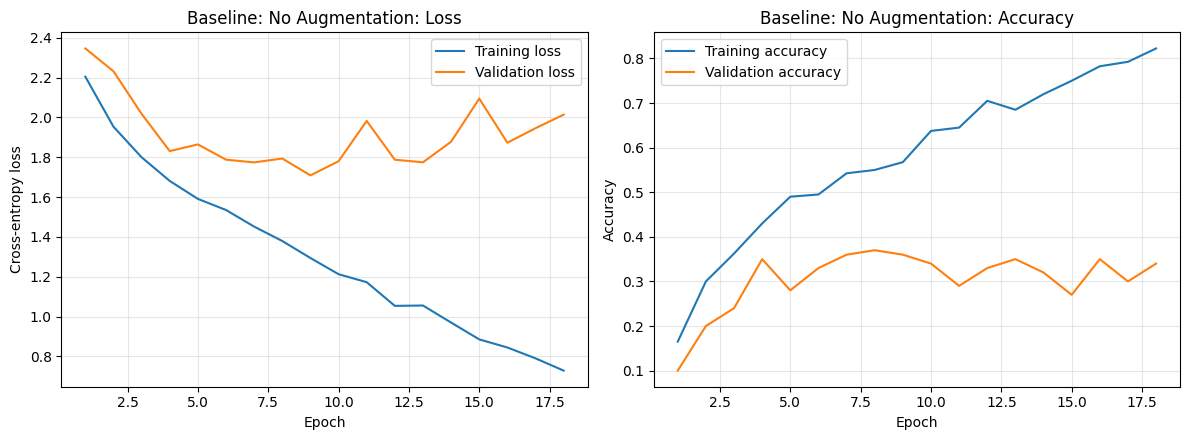

In [15]:


ABLATIONS = [
    {"name": "No augmentation", "config": "none", "mixup": False, "ls": 0.0},
    {"name": "Geometric only", "config": "geometric", "mixup": False, "ls": 0.0},
    {"name": "Photometric only", "config": "photometric", "mixup": False, "ls": 0.0},
    {"name": "Geometric + photometric", "config": "geo_photo", "mixup": False, "ls": 0.0},
    {"name": "+ Random Erasing", "config": "geo_photo_erasing", "mixup": False, "ls": 0.0},
    {"name": "+ Mixup + label smoothing", "config": "mixup", "mixup": True, "ls": 0.1},
    {"name": "Final model", "config": "final", "mixup": True, "ls": 0.05},
    {"name": "Final + RandomGrayscale", "config": "final_gray", "mixup": True, "ls": 0.05},
]

all_results = []
histories_for_plot = {}


for exp in ABLATIONS:
    for seed in RUN_SEEDS:
        print(f"\n{exp['name']} | Seed: {seed}")

        model, history, result = train_one_run(
            config=exp["config"],
            seed=seed,
            epochs=FINAL_EPOCHS,
            patience=PATIENCE,
            use_mixup=exp["mixup"],
            label_smoothing=exp["ls"],
            weight_decay=1e-4
        )

        result["experiment"] = exp["name"]
        all_results.append(result)

        histories_for_plot[(exp["name"], seed)] = history


        torch.save(
            model.state_dict(),
            OUTPUT_DIR / f"{exp['config']}_seed{seed}.pt"
        )


results_df = pd.DataFrame(all_results)
results_df.to_csv(OUTPUT_DIR / "ablation_val_results.csv", index=False)


summary = results_df.groupby("experiment", sort=False).agg(
    mean_accuracy=("best_val_acc", "mean"),
    std_accuracy=("best_val_acc", "std")
).reset_index()

summary.to_csv(OUTPUT_DIR / "ablation_val_summary.csv", index=False)

print("\nValidation Results:")
print(summary.to_string(index=False))


best_experiment = summary.loc[
    summary["mean_accuracy"].idxmax(), "experiment"
]

print("\nBest configuration:", best_experiment)


plot_history(
    histories_for_plot[("No augmentation", RUN_SEEDS[0])],
    "Baseline: No Augmentation",
    OUTPUT_DIR / "baseline_learning_curves.png"
)

In [53]:
# FINAL test evaluation
test_rows = []
clean_loader, shifted_loader = make_test_loaders()
for exp in ABLATIONS:
    for run_seed in RUN_SEEDS:
        ckpt = torch.load(
    OUTPUT_DIR / f"{exp['config']}_seed{run_seed}.pt",
    map_location=device
)
model = SmallInceptionCNN(dropout=0.30).to(device)

ckpt = torch.load(
    OUTPUT_DIR / f"{exp['config']}_seed{run_seed}.pt",
    map_location=device
)

model.load_state_dict(ckpt)

_, clean_acc = evaluate(model, clean_loader)
_, shifted_acc = evaluate(model, shifted_loader)

_, clean_acc = evaluate(model, clean_loader)       # clean_test: reporting only
_, shifted_acc = evaluate(model, shifted_loader)   # shifted_test
test_rows.append({"experiment": exp["name"], "seed": run_seed,
                          "clean_test_acc": clean_acc, "shifted_test_acc": shifted_acc})

raw_results = results_df.merge(
    pd.DataFrame(test_rows),
    on=["experiment", "seed"]
)

print("Best experiment:", best_experiment)
raw_results.to_csv(OUTPUT_DIR / "ablation_raw_results.csv", index=False)
summary = raw_results.groupby("experiment", sort=False).agg(
    val_mean=("best_val_acc", "mean"), val_std=("best_val_acc", "std"),
    clean_mean=("clean_test_acc", "mean"), clean_std=("clean_test_acc", "std"),
    shifted_mean=("shifted_test_acc", "mean"), shifted_std=("shifted_test_acc", "std"),
    epoch_mean=("best_epoch", "mean")).reset_index()
summary.to_csv(OUTPUT_DIR / "ablation_summary.csv", index=False)
print("\n", summary.to_string(index=False))

final_rows = raw_results[raw_results["experiment"] == best_experiment]
FINAL_SHIFTED_MEAN, FINAL_SHIFTED_STD = final_rows["shifted_test_acc"].mean(), final_rows["shifted_test_acc"].std()
FINAL_CLEAN_MEAN, FINAL_CLEAN_STD = final_rows["clean_test_acc"].mean(), final_rows["clean_test_acc"].std()
print(f"\nSELECTED MODEL ({best_experiment}) over seeds {RUN_SEEDS}:")
print(f"  shifted_test: {100*FINAL_SHIFTED_MEAN:.2f} ± {100*FINAL_SHIFTED_STD:.2f} %")
print(f"  clean_test  : {100*FINAL_CLEAN_MEAN:.2f} ± {100*FINAL_CLEAN_STD:.2f} %")

Best experiment: Photometric only

              experiment  val_mean  val_std  clean_mean  clean_std  shifted_mean  shifted_std  epoch_mean
Final + RandomGrayscale      0.39      NaN      0.3644        NaN        0.1696          NaN        11.0

SELECTED MODEL (Photometric only) over seeds [42, 123, 2026]:
  shifted_test: nan ± nan %
  clean_test  : nan ± nan %


In [54]:

test_rows = []

for exp in ABLATIONS:
    for seed in RUN_SEEDS:
        path = OUTPUT_DIR / f"{exp['config']}_seed{seed}.pt"

        model = SmallInceptionCNN(dropout=0.30).to(device)
        weights = torch.load(path, map_location=device)
        model.load_state_dict(weights)

        _, clean_acc = evaluate(model, clean_loader)
        _, shifted_acc = evaluate(model, shifted_loader)

        test_rows.append({
            "experiment": exp["name"],
            "seed": seed,
            "clean_test_acc": clean_acc,
            "shifted_test_acc": shifted_acc
        })

        print(
            f"{exp['name']} | seed={seed} | "
            f"clean={clean_acc:.4f} | shifted={shifted_acc:.4f}"
        )

test_df = pd.DataFrame(test_rows)

No augmentation | seed=42 | clean=0.3578 | shifted=0.1195
No augmentation | seed=123 | clean=0.3180 | shifted=0.1340
No augmentation | seed=2026 | clean=0.3823 | shifted=0.1375
Geometric only | seed=42 | clean=0.3555 | shifted=0.1675
Geometric only | seed=123 | clean=0.3419 | shifted=0.1598
Geometric only | seed=2026 | clean=0.3757 | shifted=0.1589
Photometric only | seed=42 | clean=0.3619 | shifted=0.1497
Photometric only | seed=123 | clean=0.4582 | shifted=0.1777
Photometric only | seed=2026 | clean=0.3837 | shifted=0.1460
Geometric + photometric | seed=42 | clean=0.3820 | shifted=0.1728
Geometric + photometric | seed=123 | clean=0.3720 | shifted=0.1722
Geometric + photometric | seed=2026 | clean=0.3380 | shifted=0.1454
+ Random Erasing | seed=42 | clean=0.3568 | shifted=0.1769
+ Random Erasing | seed=123 | clean=0.4061 | shifted=0.2039
+ Random Erasing | seed=2026 | clean=0.3996 | shifted=0.2063
+ Mixup + label smoothing | seed=42 | clean=0.3525 | shifted=0.1791
+ Mixup + label smoo

In [67]:

raw_results = raw_results.drop(
    columns=["clean_test_acc", "shifted_test_acc"],
    errors="ignore"
)


raw_results = raw_results.merge(
    test_df,
    on=["experiment", "seed"],
    how="left",
    validate="one_to_one"
)

print(raw_results[
    ["experiment", "seed", "clean_test_acc", "shifted_test_acc"]
])

                experiment  seed  clean_test_acc  shifted_test_acc
0  Final + RandomGrayscale  2026          0.3644            0.1696


In [71]:
raw_results = results_df.copy()

raw_results = raw_results.drop(
    columns=["clean_test_acc", "shifted_test_acc"],
    errors="ignore"
)

raw_results = raw_results.merge(
    test_df,
    on=["experiment", "seed"],
    how="left",
    validate="one_to_one"
)

summary = raw_results.groupby("experiment", sort=False).agg(
    val_mean=("best_val_acc", "mean"),
    val_std=("best_val_acc", "std"),
    clean_mean=("clean_test_acc", "mean"),
    clean_std=("clean_test_acc", "std"),
    shifted_mean=("shifted_test_acc", "mean"),
    shifted_std=("shifted_test_acc", "std")
).reset_index()

print(summary.to_string(index=False))

               experiment  val_mean  val_std  clean_mean  clean_std  shifted_mean  shifted_std
          No augmentation  0.370000 0.020000    0.352700   0.032452      0.130333     0.009544
           Geometric only  0.390000 0.010000    0.357700   0.017007      0.162067     0.004727
         Photometric only  0.420000 0.036056    0.401267   0.050496      0.157800     0.017333
  Geometric + photometric  0.390000 0.045826    0.364000   0.023065      0.163467     0.015649
         + Random Erasing  0.406667 0.020817    0.387500   0.026785      0.195700     0.016325
+ Mixup + label smoothing  0.380000 0.017321    0.344500   0.008102      0.178400     0.003306
              Final model  0.400000 0.017321    0.358133   0.014911      0.165933     0.009546
  Final + RandomGrayscale  0.400000 0.026458    0.382133   0.021608      0.180733     0.011409


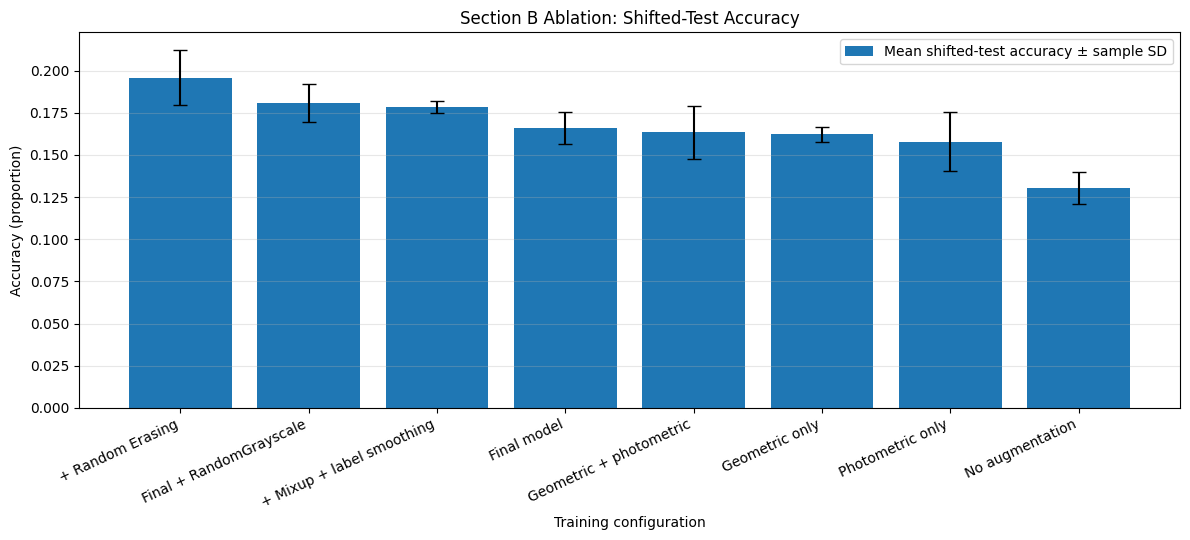

In [72]:
# Plot shifted-test mean ± sample SD
plot_df = summary.sort_values("shifted_mean", ascending=False)
fig, ax = plt.subplots(figsize=(12, 5.5))
x = np.arange(len(plot_df))
ax.bar(x, plot_df["shifted_mean"], yerr=plot_df["shifted_std"].fillna(0), capsize=5,
       label="Mean shifted-test accuracy ± sample SD")
ax.set_xticks(x); ax.set_xticklabels(plot_df["experiment"], rotation=25, ha="right")
ax.set_title("Section B Ablation: Shifted-Test Accuracy")
ax.set_xlabel("Training configuration"); ax.set_ylabel("Accuracy (proportion)")
ax.legend(); ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "shifted_test_ablation.png", dpi=150, bbox_inches="tight")
plt.show()

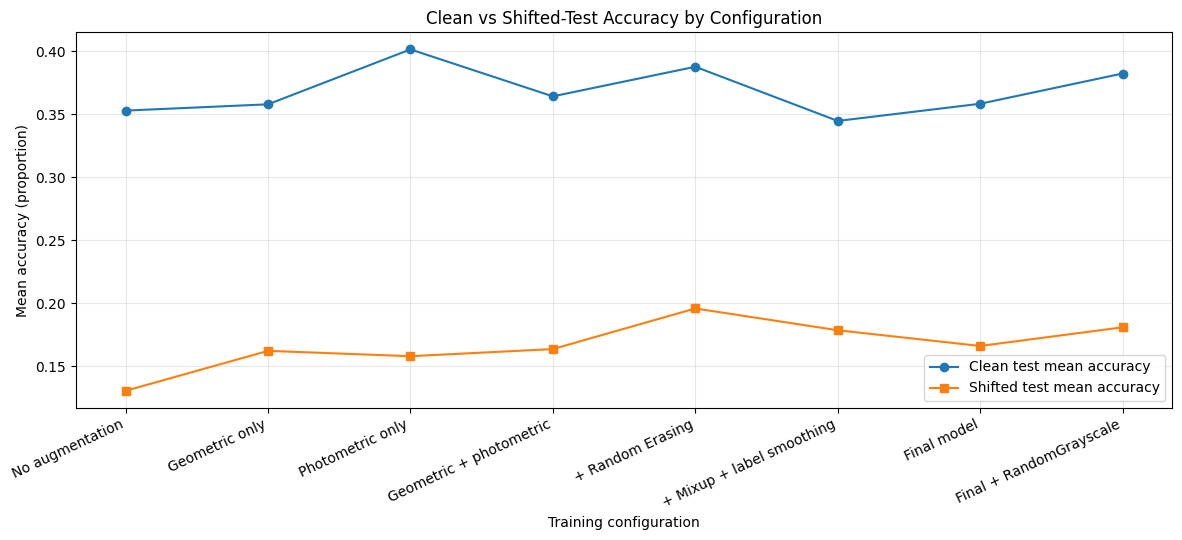

In [73]:
# Plot clean vs shifted test accuracy
fig, ax = plt.subplots(figsize=(12, 5.5))
x = np.arange(len(summary))
ax.plot(x, summary["clean_mean"], marker="o", label="Clean test mean accuracy")
ax.plot(x, summary["shifted_mean"], marker="s", label="Shifted test mean accuracy")
ax.set_xticks(x); ax.set_xticklabels(summary["experiment"], rotation=25, ha="right")
ax.set_title("Clean vs Shifted-Test Accuracy by Configuration")
ax.set_xlabel("Training configuration"); ax.set_ylabel("Mean accuracy (proportion)")
ax.legend(); ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "clean_vs_shifted_accuracy.png", dpi=150, bbox_inches="tight")
plt.show()